# EDA 00 — So sánh các bộ dữ liệu

Notebook này đọc các file tóm tắt `reports/eda/*.json` do từng notebook EDA sinh ra và so sánh:
kích thước, tỉ lệ nợ xấu, mức thiếu dữ liệu, độ lệch phân phối và sức phân biệt của biến mạnh nhất.
Chạy **sau** các notebook `eda_01` … `eda_08`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"
import json

In [2]:
ORDER = ["hmeq", "fico_heloc", "taiwan_default_credit", "give_me_some_credit",
         "german_credit", "south_german_credit", "home_credit", "lending_club"]
S = {n: json.load(open(ROOT / "reports" / "eda" / f"{n}.json")) for n in ORDER}
tab = pd.DataFrame({
    n: {
        "rows (có nhãn)": s["target"]["n"],
        "features": s["overview"]["features"],
        "bad_rate_%": s["target"]["bad_rate_pct"],
        "good:bad": s["target"]["imbalance_ratio"],
        "ô thiếu %": s["overview"]["cells_missing_pct"],
        "cột có thiếu": s["overview"]["features_with_missing"],
        "dòng trùng": s["overview"]["duplicate_rows"],
        "biến số |skew|>2": f'{s["n_numeric_abs_skew_gt2"]}/{s["n_numeric"]}',
        "max |skew|": round(s["max_abs_skew"], 1),
        "AUC đơn biến tốt nhất": round(max(s["top_auc"].values()), 3),
    } for n, s in S.items()
}).T
tab

,rows (có nhãn),features,bad_rate_%,good:bad,ô thiếu %,cột có thiếu,dòng trùng,biến số |skew|>2,max |skew|,AUC đơn biến tốt nhất
hmeq,5960,12.0,19.95,4.01,6.8,11.0,0.0,6/10,5.3,0.672
fico_heloc,9871,23.0,52.03,0.92,0.0,0.0,1.0,6/23,7.1,0.769
taiwan_default_credit,30000,24.0,22.12,3.52,0.0,0.0,0.0,12/23,30.5,0.69
give_me_some_credit,150000,10.0,6.68,13.96,2.04,2.0,609.0,7/10,114.0,0.778
german_credit,1000,20.0,30.0,2.33,0.0,0.0,0.0,0/6,1.9,0.629
south_german_credit,1000,20.0,30.0,2.33,0.0,0.0,0.0,1/17,3.3,0.708
home_credit,307511,121.0,8.07,11.39,24.4,67.0,0.0,45/73,391.6,0.679
lending_club,1348099,23.0,19.98,4.0,0.41,11.0,0.0,7/16,46.2,0.683


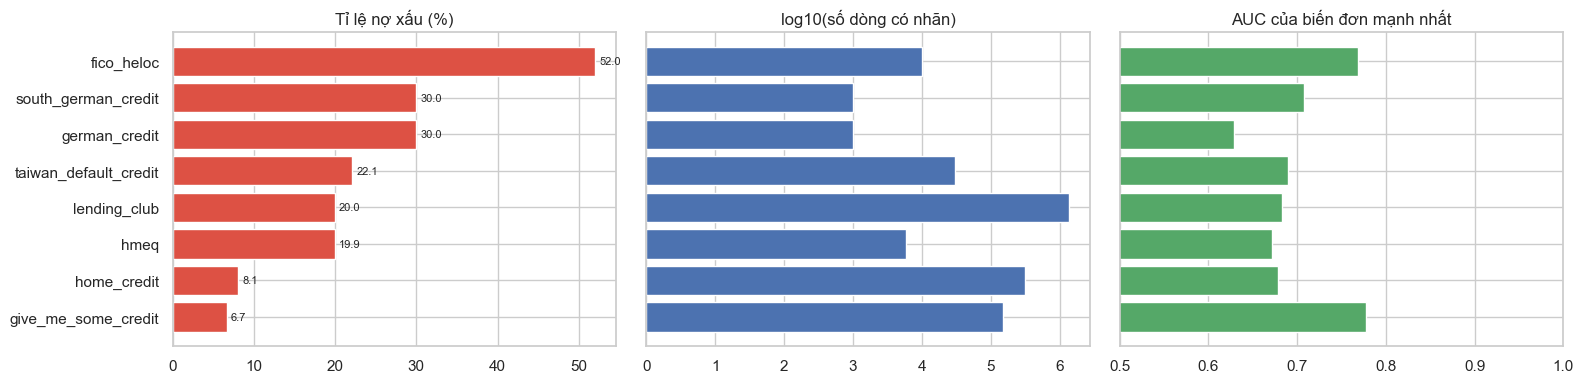

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t = tab.sort_values("bad_rate_%")
axes[0].barh(t.index, t["bad_rate_%"].astype(float), color="#DD5144")
axes[0].set_title("Tỉ lệ nợ xấu (%)")
for y, v in enumerate(t["bad_rate_%"].astype(float)):
    axes[0].text(v + 0.5, y, f"{v:.1f}", va="center", fontsize=8)
axes[1].barh(t.index, np.log10(t["rows (có nhãn)"].astype(float)), color="#4C72B0")
axes[1].set_title("log10(số dòng có nhãn)")
axes[2].barh(t.index, t["AUC đơn biến tốt nhất"].astype(float), color="#55A868")
axes[2].set_xlim(0.5, 1); axes[2].set_title("AUC của biến đơn mạnh nhất")
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
eda.savefig(fig, "comparison_overview")
plt.show()

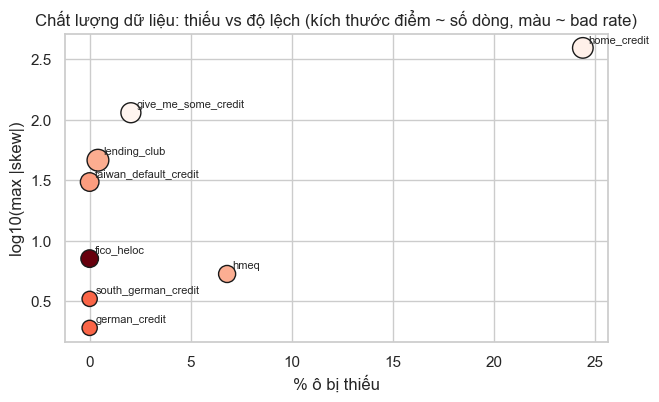

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
x = tab["ô thiếu %"].astype(float); y = tab["max |skew|"].astype(float)
ax.scatter(x, np.log10(y), s=np.log10(tab["rows (có nhãn)"].astype(float)) * 40, c=tab["bad_rate_%"].astype(float),
           cmap="Reds", edgecolor="k")
for n in tab.index:
    ax.annotate(n, (x[n], np.log10(y[n])), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("% ô bị thiếu"); ax.set_ylabel("log10(max |skew|)")
ax.set_title("Chất lượng dữ liệu: thiếu vs độ lệch (kích thước điểm ~ số dòng, màu ~ bad rate)")
eda.savefig(fig, "comparison_quality")
plt.show()

In [5]:
tab.to_csv(ROOT / "reports" / "tables" / "eda_comparison.csv")
print("Đã lưu reports/tables/eda_comparison.csv")

Đã lưu reports/tables/eda_comparison.csv
